In [1]:
import numpy as np

# Made-up toy data: hours of safety training per worker (x) vs. TRIR (y).
# Five points on purpose, so every number can be checked by hand
x = np.array([2, 4, 6, 8, 10], dtype=float)
y = np.array([7, 6, 4, 3, 1], dtype=float)


def mse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Average of (prediction - actual) squared."""
    return np.mean((y_pred - y_true) ** 2)


# A guessed line: start at 7 and drop half a point of TRIR per training hour
w, b = -0.5, 7.0
y_pred = w * x + b
print(mse(y, y_pred))

0.6


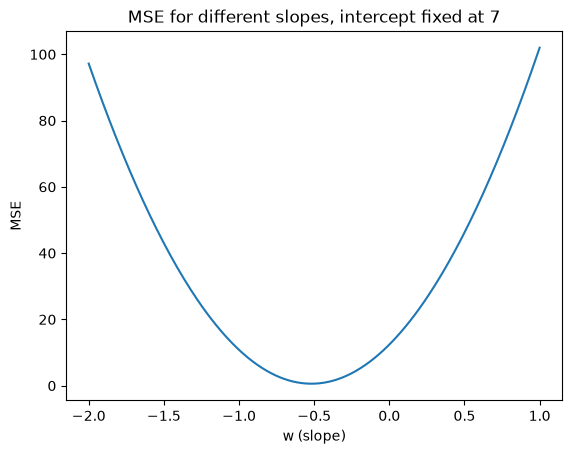

In [2]:
import matplotlib.pyplot as plt

# Keep the intercept fixed so we can see loss change along one weight at a time
b_fixed = 7.0
w_values = np.linspace(-2, 1, 200)
losses = [mse(y, w_try * x + b_fixed) for w_try in w_values]

plt.plot(w_values, losses)
plt.xlabel("w (slope)")
plt.ylabel("MSE")
plt.title("MSE for different slopes, intercept fixed at 7")
plt.show()

In [3]:
def gradient_descent(x, y, learning_rate=0.01, steps=5000):
    # Start from a flat line at zero; gradient descent will walk it downhill
    w, b = 0.0, 0.0

    for step in range(steps):
        y_pred = w * x + b
        error = y_pred - y

        grad_w = np.mean(2 * error * x)
        grad_b = np.mean(2 * error)
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

    return w, b


w_gd, b_gd = gradient_descent(x, y)
print(f"w = {w_gd:.3f}, b = {b_gd:.3f}, MSE = {mse(y, w_gd * x + b_gd):.3f}")

w = -0.750, b = 8.700, MSE = 0.060


In [4]:
# Same starting point every time, just more steps, so you can watch the line walk downhill
for n_steps in [1, 10, 100, 1000, 5000]:
    w_s, b_s = gradient_descent(x, y, steps=n_steps)
    print(f"{n_steps:>5} steps: w = {w_s:7.3f}, b = {b_s:6.3f}, MSE = {mse(y, w_s * x + b_s):.3f}")

    1 steps: w =   0.384, b =  0.084, MSE = 13.631
   10 steps: w =   0.392, b =  0.363, MSE = 12.699
  100 steps: w =   0.077, b =  2.657, MSE = 6.700
 1000 steps: w =  -0.717, b =  8.458, MSE = 0.071
 5000 steps: w =  -0.750, b =  8.700, MSE = 0.060


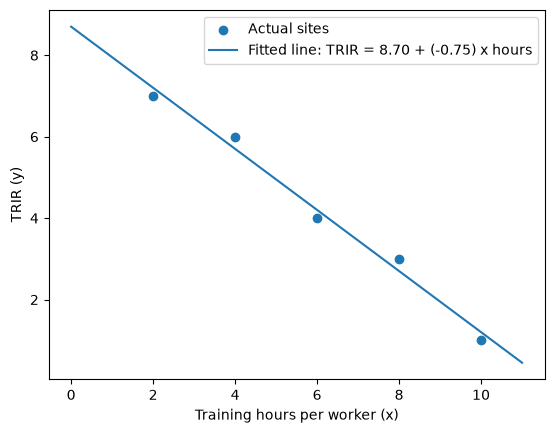

In [5]:
# The five toy sites as dots, plus the line gradient descent found
plt.scatter(x, y, label="Actual sites")

# Start the line at x = 0 so you can see where it begins
x_line = np.linspace(0, 11, 100)
plt.plot(x_line, b_gd + w_gd * x_line, label=f"Fitted line: TRIR = {b_gd:.2f} + ({w_gd:.2f}) x hours")

plt.xlabel("Training hours per worker (x)")
plt.ylabel("TRIR (y)")
plt.legend()
plt.show()

In [6]:
# One row per site: a column of 1s (pairs with b), then training hours (pairs with w)
X = np.column_stack([np.ones_like(x), x])

# Same order as X's columns: b first, then w
theta = np.array([b_gd, w_gd])

print(X)

# TODO: print the predictions for all five sites in one line using @
print (X @ theta)

[[ 1.  2.]
 [ 1.  4.]
 [ 1.  6.]
 [ 1.  8.]
 [ 1. 10.]]
[7.19999989 5.69999993 4.19999997 2.70000001 1.20000005]


In [8]:
def normal_equation(X, y):
    """Jump straight to the bottom of the bowl: theta = (X^T X)^-1 X^T y."""
    # TODO: one line. np.linalg.inv() inverts a matrix, .T transposes, @ multiplies
    return np.linalg.inv(X.T @ X) @ X.T @ y

theta_ne = normal_equation(X, y)
print(theta_ne)

[ 8.7  -0.75]


In [9]:
import pandas as pd
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
train = pd.read_csv(ROOT / "data" / "processed" / "train.csv", low_memory=False)

# Each distinct value becomes one one-hot column, so this is how wide each feature would make X
for col in ["naics_code", "state", "establishment_type", "size"]:
    print(f"{col}: {train[col].nunique():,} distinct values")

naics_code: 1,180 distinct values
state: 61 distinct values
establishment_type: 3 distinct values
size: 5 distinct values


In [10]:
# The 50 states plus DC; anything else in the column is an extra worth seeing
STATES_AND_DC = set("""
AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO
MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC
""".split())

extras = train.loc[~train["state"].isin(STATES_AND_DC), "state"].value_counts(dropna=False)
print(extras)

state
PR    1069
GU      55
VI      38
MP      11
AA       4
AS       3
AP       2
AE       2
PW       1
MH       1
Name: count, dtype: int64


In [11]:
counts = train["naics_code"].value_counts()
print(f"6-digit codes with fewer than 30 sites: {(counts < 30).sum()} of {len(counts)}")

# Truncating the code groups sites into broader industries
for digits in [2, 3]:
    prefix = train["naics_code"].astype(str).str[:digits]
    print(f"{digits}-digit level: {prefix.nunique()} groups, smallest has {prefix.value_counts().min()} sites")

6-digit codes with fewer than 30 sites: 445 of 1180
2-digit level: 32 groups, smallest has 1 sites
3-digit level: 120 groups, smallest has 1 sites


In [12]:
# Smallest groups first, since that's where junk codes tend to hide
prefix2 = train["naics_code"].astype(str).str[:2]
print(prefix2.value_counts().sort_values().head(12))

naics_code
46       1
63       1
59       1
95       1
24       1
99       4
28       4
87      15
21     555
52     660
55    1379
61    2187
Name: count, dtype: int64


In [13]:
from sitebench.features import SiteFeatures

val = pd.read_csv(ROOT / "data" / "processed" / "val.csv", low_memory=False)

# Learn the encoding rules from train only, then apply them to both
features = SiteFeatures().fit(train)
X_train = features.transform(train)
X_val = features.transform(val)

print("X_train:", X_train.shape, " X_val:", X_val.shape)
print(X_train.columns[:8].tolist())

X_train: (273568, 161)  X_val: (58622, 161)
['annual_average_employees', 'hours_per_employee', 'industry_111', 'industry_112', 'industry_113', 'industry_114', 'industry_115', 'industry_211']


In [14]:
from sklearn.linear_model import LinearRegression

y_train = train["trir"].to_numpy()

# Your version needs the column of 1s for b; scikit-learn adds its own intercept
X_train_ne = np.column_stack([np.ones(len(X_train)), X_train.to_numpy()])
theta = normal_equation(X_train_ne, y_train)

sk = LinearRegression().fit(X_train, y_train)

print("Intercept, yours:", round(theta[0], 4), " scikit-learn:", round(sk.intercept_, 4))
print("Largest difference between any two matching weights:", np.abs(theta[1:] - sk.coef_).max())

Intercept, yours: 9.6324  scikit-learn: 9.6324
Largest difference between any two matching weights: 2.7806958124987347e-12


In [15]:
X_val_ne = np.column_stack([np.ones(len(X_val)), X_val.to_numpy()])
y_val = val["trir"].to_numpy()

pred_val = X_val_ne @ theta
# Simplest possible model: the training average, for every site
pred_baseline = np.full_like(y_val, y_train.mean())

for name, pred in [("Always the average", pred_baseline), ("Your regression", pred_val)]:
    print(f"{name:>20}: RMSE = {np.sqrt(mse(y_val, pred)):.3f}")

  Always the average: RMSE = 11.693
     Your regression: RMSE = 11.427


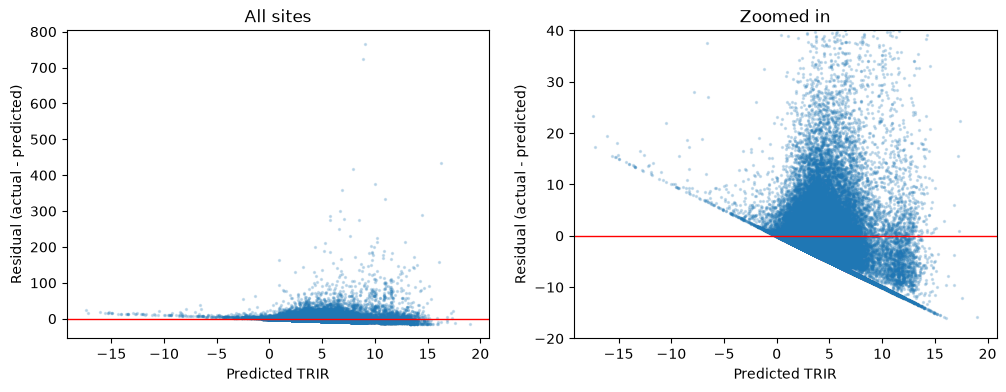

Share of sites the model over-predicts: 67%


In [16]:
# Positive residual = the site had more injuries than the model expected
residuals = y_val - pred_val

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ylim, title in [(axes[0], None, "All sites"), (axes[1], (-20, 40), "Zoomed in")]:
    # Tiny, faint dots so 58,000 points don't turn into one solid blob
    ax.scatter(pred_val, residuals, s=2, alpha=0.2)
    ax.axhline(0, color="red", linewidth=1)
    ax.set_xlabel("Predicted TRIR")
    ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(title)
    if ylim:
        ax.set_ylim(ylim)
plt.show()

print(f"Share of sites the model over-predicts: {(residuals < 0).mean():.0%}")

In [17]:
# log1p(t) = log(1 + t), so zero-injury sites map to 0 instead of negative infinity
y_train_log = np.log1p(y_train)
theta_log = normal_equation(X_train_ne, y_train_log)

# expm1 reverses log1p, turning predictions back into TRIR; clip floors the rare small negative at 0
pred_val_log = np.clip(np.expm1(X_val_ne @ theta_log), 0, None)

print(f"Lowest prediction, original model: {pred_val.min():.2f}   log model: {pred_val_log.min():.2f}")
print(f"RMSE, original model: {np.sqrt(mse(y_val, pred_val)):.3f}   log model: {np.sqrt(mse(y_val, pred_val_log)):.3f}")
print(f"Median miss, original model: {np.median(np.abs(y_val - pred_val)):.3f}   log model: {np.median(np.abs(y_val - pred_val_log)):.3f}")

Lowest prediction, original model: -17.42   log model: 0.00
RMSE, original model: 11.427   log model: 11.847
Median miss, original model: 3.379   log model: 1.776


In [ ]:
Set-Location ~\sitebench

# -Force replaces the older copy in notebooks/ with tonight's version
Move-Item -Force src\sitebench\02_linear_regression.ipynb.ipynb notebooks\02_linear_regression.ipynb

git add notebooks/02_linear_regression.ipynb
git commit -m "Add features, real-data regression, residuals, and log model"
git push